# Task 2.2: phase-flip relaxation

We initialize the memory in the normalized even cat $\lvert C_+\rangle\propto\lvert\alpha\rangle+\lvert-\alpha\rangle$ and the buffer in vacuum. The supplied two-mode Hamiltonian and loss channels are retained, with $\epsilon_d=g_2\alpha^2$ throughout the sweep. The physical target $\alpha=2.1$ is included.

A lost memory photon switches the cat's even/odd parity. We track $\Pi=(-1)^{a^\dagger a}$ and fit its expectation value after the initial transient:

$$
\langle\Pi(t)\rangle=\Pi_\infty+A e^{-\Gamma_Z(t-t_{\mathrm{fit}})},\qquad t_{\mathrm{fit}}=1\ \mathrm{\mu s}.
$$

The steady parity $\Pi_\infty$, amplitude $A$ and decay rate $\Gamma_Z$ are fitted together. A finite offset is essential when the coherent states overlap. This avoids bias from forcing parity to decay to zero. The lifetime is $T_Z=1/\Gamma_Z$; each parity reversal changes its sign, giving the large-cat prediction $\Gamma_Z\simeq2\kappa_a\alpha^2$.

The notebook loads saved results by default. Set `RERUN=True` to recompute the trajectories, cutoff study, fitting-window checks and independent Dynamiqs integrations.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import Image, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/config.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
RERUN = False


In [2]:
if RERUN:
    from tasks.task_2_2 import main
    main()
result = json.loads((ROOT / "results/task_2_2.json").read_text())
assert result["complete"]
summary = pd.DataFrame([{
    "alpha": row["alpha"], "Gamma (1/us)": row["fit"]["gamma_per_us"],
    "T (us)": row["fit"]["tau_us"], "offset": row["fit"]["offset"],
    "cutoff change (%)": 100*row["checks"]["cutoff_relative_change"],
} for row in result["cases"]])
display(summary)


,alpha,Gamma (1/us),T (us),offset,cutoff change (%)
0,1.2,0.168535,5.933472,0.114962,4.000358e-07
1,1.5,0.262159,3.814479,0.023112,3.235457e-07
2,1.8,0.377814,2.646808,0.003237,3.220585e-07
3,2.1,0.514559,1.943412,0.000317,2.191127e-05
4,2.4,0.672337,1.487348,0.000020,2.513725e-04


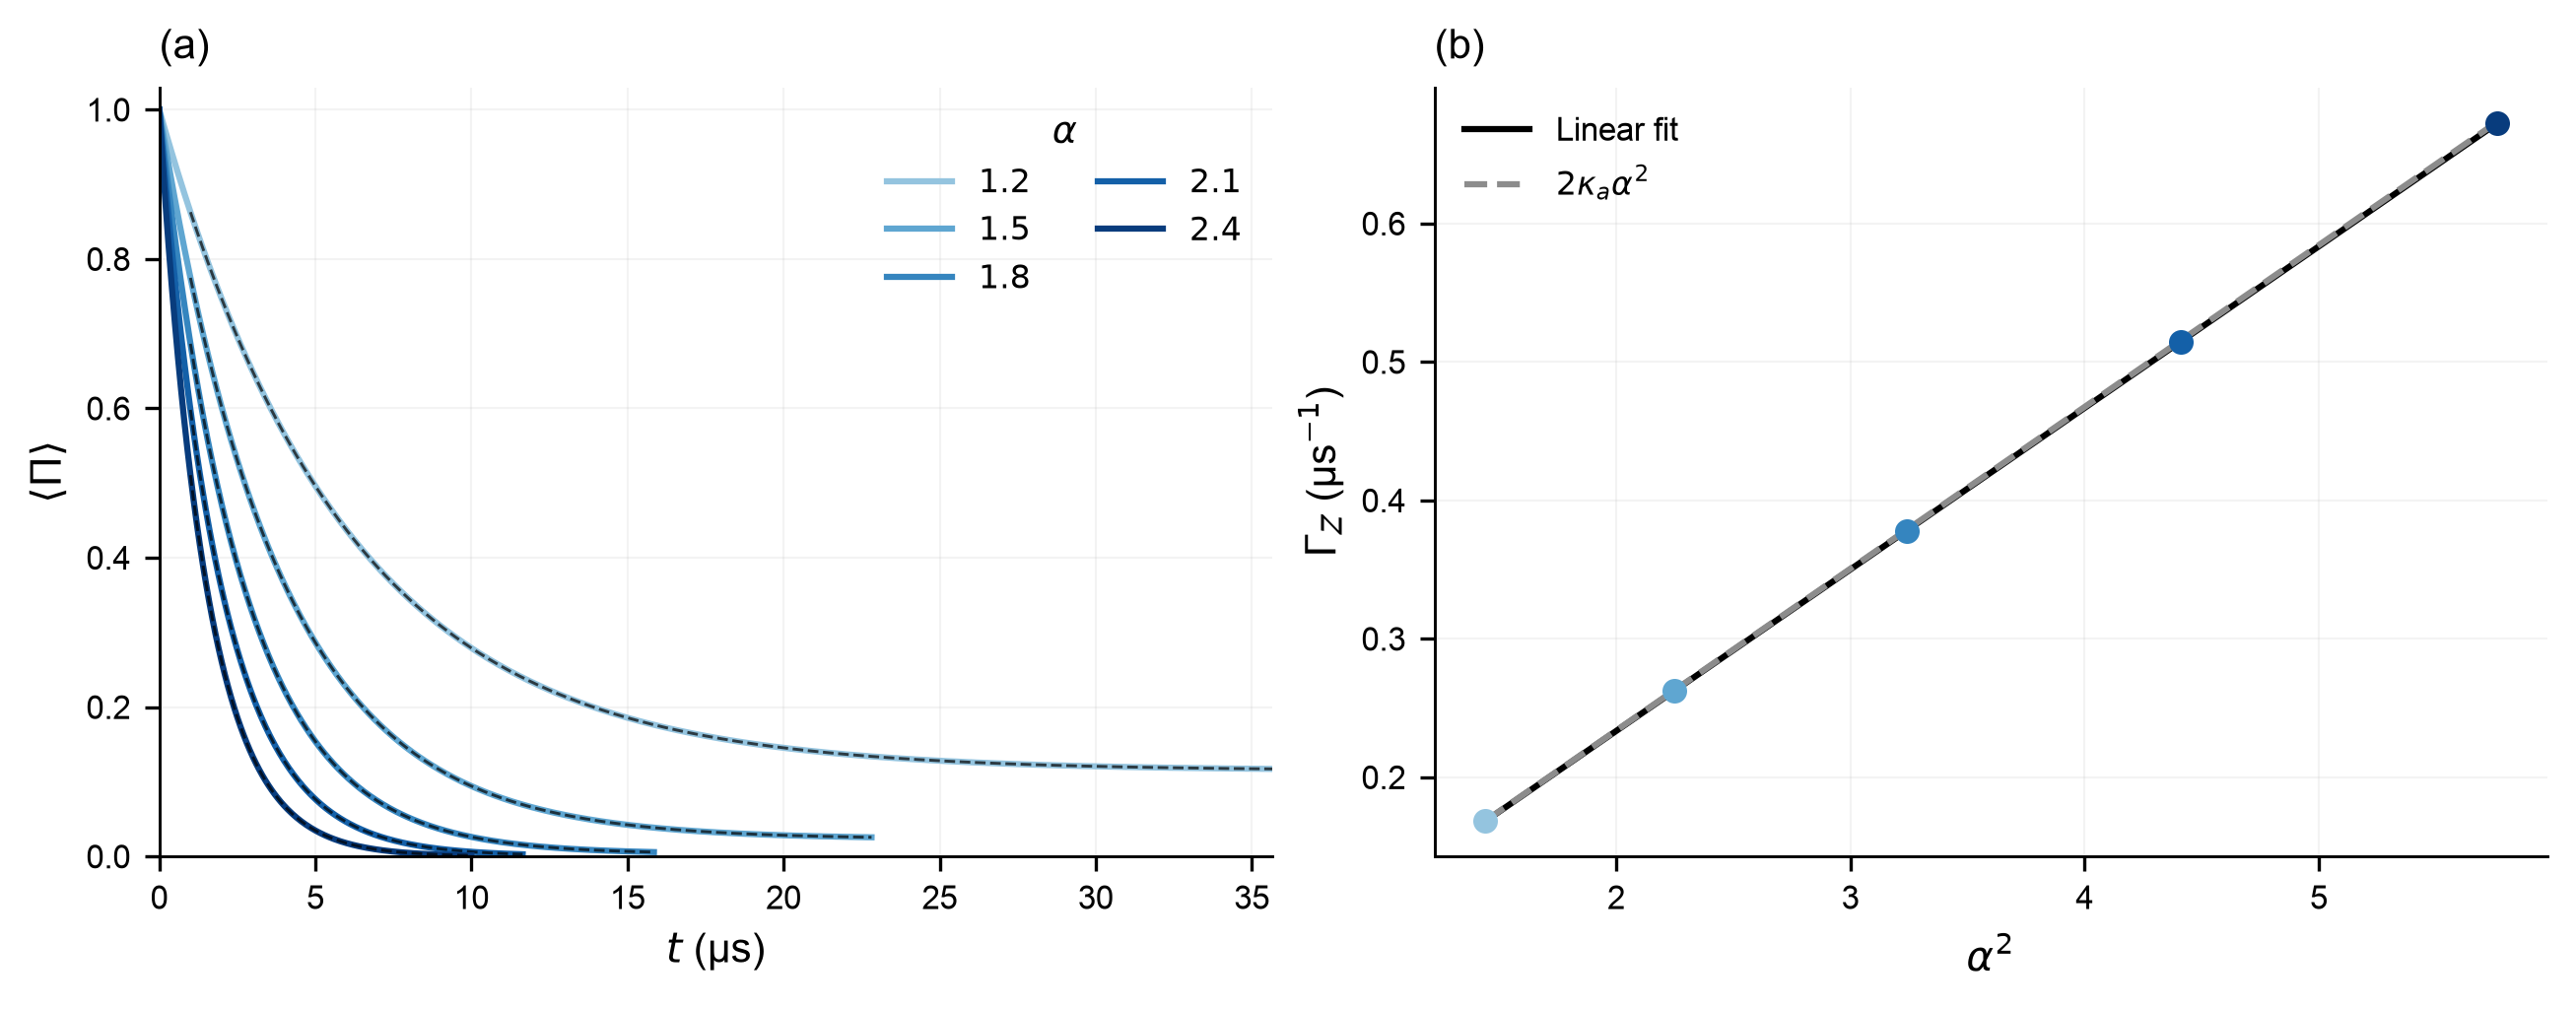

In [3]:
display(Image(filename=str(ROOT / "figures/task_2_2_phase_flips.png")))

**Phase-flip relaxation and cat-size scaling.** Full two-mode dynamics from the even cat $\lvert C_+\rangle_a\lvert0\rangle_b$ at $(N_a,N_b)=(24,8)$, with $\epsilon_d=g_2\alpha^2$. Colors identify $\alpha$. (a) Memory parity $\langle\Pi\rangle$, with $\Pi=(-1)^{a^\dagger a}$; black dashes fit $\Pi_\infty+Ae^{-\Gamma_Z(t-t_{\mathrm{fit}})}$ from $t_{\mathrm{fit}}=1$ µs. The fitted offset $\Pi_\infty$ accommodates the finite steady parity of overlapping codewords. (b) Fitted $\Gamma_Z$ versus $\alpha^2$; the black line is a free-intercept linear regression and gray dashes show $2\kappa_a\alpha^2$ using the supplied memory-loss rate. The physical target $\alpha=2.1$ is included. Cutoff, fitting-window, solver and independent Dynamiqs checks are recorded with the numerical results.

## Interpretation

In the ideal cat space, single-photon loss takes the even cat to the odd cat at rate $\kappa_a\alpha^2\tanh(\alpha^2)$ and the odd cat to the even cat at rate $\kappa_a\alpha^2\coth(\alpha^2)$. The corresponding first-order relaxation rate and steady parity are

$$
\Gamma_Z^{(1)}=2\kappa_a\alpha^2\coth(2\alpha^2),\qquad
\Pi_\infty^{(1)}=\operatorname{sech}(2\alpha^2).
$$

For sufficiently separated codewords these reduce to $\Gamma_Z\simeq2\kappa_a\alpha^2$ and an approximately zero offset. These formulas motivate the fit; the reported rates come from the full two-mode trajectories. See the [rate report](../docs/task_2_rates.md) for the fitted slope, numerical checks and target-amplitude result.

In [4]:
checks = pd.DataFrame([{
    "alpha": row["alpha"],
    "fit/eigenvalue difference (%)": 100*row["checks"]["fit_vs_eigen_relative_change"],
    "Dynamiqs rate difference (%)": 100*row["checks"]["dynamiqs_rate_relative_change"],
    "fitting-window spread (%)": 100*row["checks"]["window_relative_spread"],
    "max memory top-2 (%)": 100*row["diagnostics"]["max_top2_a"],
    "max buffer top-1 (%)": 100*row["diagnostics"]["max_top1_b"],
} for row in result["cases"]])
display(checks)
print("Scaling fit:")
for key, value in result["scaling_fit"].items():
    print(f"  {key}: {value}")


,alpha,fit/eigenvalue difference (%),Dynamiqs rate difference (%),fitting-window spread (%),max memory top-2 (%),max buffer top-1 (%)
0,1.2,5.311853e-08,2.090334e-06,0.000112,2.761854e-14,6.433853e-10
1,1.5,5.144032e-07,2.511575e-06,0.000044,4.740811e-11,3.544906e-08
2,1.8,2.483063e-06,1.312505e-06,0.000087,6.296736e-09,2.399032e-07
3,2.1,1.750503e-06,1.141208e-06,0.000094,4.492919e-07,3.599516e-07
4,2.4,4.916671e-06,2.409191e-08,0.000152,3.189526e-05,4.642582e-06


Scaling fit:
  slope_per_us: 0.11668539287301341
  intercept_per_us: 1.6830999639394495e-05
  r_squared: 0.9999967682854518
  predicted_slope_per_us: 0.11686724671354029
  slope_relative_error: -0.0015560719161342718
  through_origin_slope_per_us: 0.11668948926572151


## Cross-check with the eigenvalue shortcut

$\Gamma_Z$ is also the slowest nonzero eigenvalue of the even block of the Liouvillian, computed in the same run as $\Gamma_X$ in Task 2.1 (`research/s2/gx_eig.py`). The two methods share no code beyond the model parameters.

In [5]:
import sys
from research.s2.notebook_figs import load, nominal, largest
eig = largest(d for d in load("gx_two_*.json") if nominal(d) and "gamma_z_eig" in d)
pd.DataFrame([{"alpha": c["alpha"], "time domain fit (1/us)": f"{c['fit']['gamma_per_us']:.6f}",
               "eigenvalue (1/us)": f"{eig[round(c['alpha'], 2)]['gamma_z_eig']:.6f}",
               "difference": f"{abs(eig[round(c['alpha'], 2)]['gamma_z_eig'] / c['fit']['gamma_per_us'] - 1):.0e}"}
              for c in result["cases"]])

,alpha,time domain fit (1/us),eigenvalue (1/us),difference
0,1.2,0.168535,0.168535,5e-09
1,1.5,0.262159,0.262159,1e-08
2,1.8,0.377814,0.377814,2e-08
3,2.1,0.514559,0.514559,4e-08
4,2.4,0.672337,0.672336,3e-06


The fitted rates and the eigenvalues agree to at least five digits at every amplitude, including the challenge target $\alpha=2.1$ ($0.51456\ \mu\mathrm{s}^{-1}$, one phase flip every 1.94 µs).